In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
df = pd.read_csv("LTV.csv")

In [ ]:
df['revenue_usd'] = df['revenue_usd'].replace('(null)', np.nan)
df['revenue_usd'] = pd.to_numeric(df['revenue_usd'])
df['revenue_usd'].fillna(0, inplace=True)

In [4]:
df['RD'] = pd.to_datetime(df['RD'], format='%d.%m.%Y')
df['TD'] = pd.to_datetime(df['TD'].replace('(null)', np.nan), format='%d.%m.%Y', errors='coerce')

In [5]:
df['age_months'] = ((df['TD'] - df['RD']).dt.days / 30.44).round(0).astype('Int64')

In [6]:
df_6month = df[df['age_months'] <= 6]

In [7]:
ltv_data = df_6month.groupby(['customer_id', 'age_months'])['revenue_usd'].sum().reset_index()
ltv_data['cumulative_revenue'] = ltv_data.groupby('customer_id')['revenue_usd'].cumsum()

In [8]:
ltv_curve = ltv_data.groupby('age_months')['cumulative_revenue'].mean()

In [9]:
ltv_6th_month = ltv_curve.loc[6]
print(f"The estimated LifeTimeValue (LTV) of the 6th month per user is: ${ltv_6th_month:.2f}")

The estimated LifeTimeValue (LTV) of the 6th month per user is: $31.43


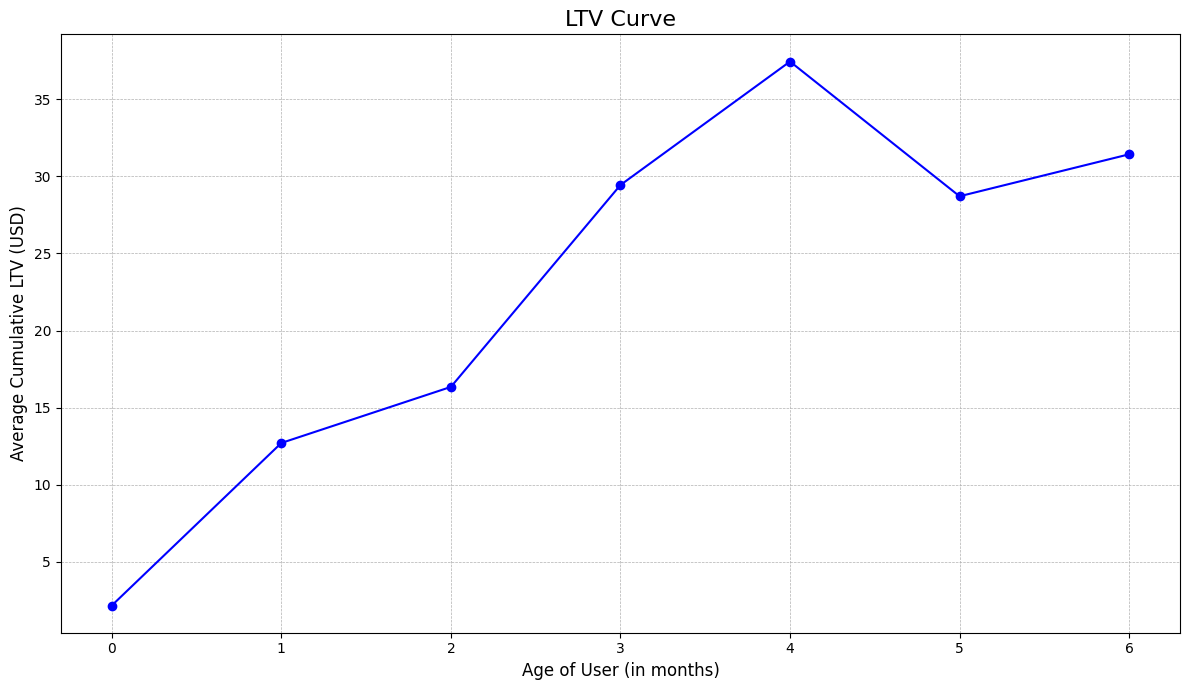

In [11]:
plt.figure(figsize=(12, 7))
ltv_curve.plot(marker='o', linestyle='-', color='b')
plt.title('LTV Curve', fontsize=16)
plt.xlabel('Age of User (in months)', fontsize=12)
plt.ylabel('Average Cumulative LTV (USD)', fontsize=12)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.xticks(np.arange(min(ltv_curve.index), max(ltv_curve.index) + 1, 1))
plt.tight_layout()
plt.show()